In [19]:
import torch
import torch.nn.functional as F
import numpy as np
import copy
import argparse
import os
import matplotlib
from typing import Tuple


class PointSampler:
    """
    Base class for point cloud samplers.

    Generates a fixed set of coordinates in the [-1, 1] domain and samples
    values from uniform grids at these locations using interpolation.

    Parameters
    ----------
    num_points : int
        The number of points to sample in the point cloud.
    device : torch.device
        The device to store coordinates on.
    """
    def __init__(self, num_points: int, device: torch.device):
        self.num_points = num_points
        self.device = device
        self.coordinates = self._generate_coordinates().to(device)

    def _generate_coordinates(self) -> torch.Tensor:
        """
        Abstract method to generate the point cloud coordinates.
        Must be implemented by subclasses.

        Returns
        -------
        torch.Tensor
            A tensor of shape (N, 2) with coordinates in the range [-1, 1].
        """
        raise NotImplementedError("Subclasses must implement _generate_coordinates")

    def sample(self, grid: torch.Tensor) -> torch.Tensor:
        """
        Samples values from a uniform grid at the pre-defined coordinates.

        Parameters
        ----------
        grid : torch.Tensor
            A uniform grid tensor of shape (B, C, H, W) defined over [-1, 1]^2.

        Returns
        -------
        torch.Tensor
            A tensor of point values of shape (B, N, C).
        """
        # The grid and coordinates are both in the [-1, 1] x [-1, 1] domain.
        bbox = ((-1.0, 1.0), (-1.0, 1.0))
        
        # grid_to_points_2d returns (B, C, N), we want (B, N, C)
        # align_corners=False is standard for grid_sample when points are not pixels.
        sampled_values = grid_to_points_2d(
            grid,
            self.coordinates,
            bbox,
            align_corners=False
        )
        return sampled_values.permute(0, 2, 1)


class LocallyDenseSampler(PointSampler):
    """
    Generates points with a locally dense region (a box) inside the [-1, 1]^2 domain.

    Parameters
    ----------
    num_points : int
        Total number of points to sample.
    device : torch.device
        The device to store coordinates on.
    box_size : Tuple[float, float]
        The (width, height) of the dense box, relative to the domain size (2x2).
    center : Tuple[float, float]
        The (x, y) center of the dense box in [-1, 1]^2.
    inner_ratio : float
        The fraction of points to be sampled inside the dense box.
    """
    def __init__(
        self,
        num_points: int,
        device: torch.device,
        box_size: Tuple[float, float] = (0.4, 0.4), # e.g., 0.4 corresponds to 20% of the 2-unit width
        center: Tuple[float, float] = (0.0, 0.0),
        inner_ratio: float = 0.6
    ):
        self.box_w, self.box_h = box_size
        self.center_x, self.center_y = center
        self.inner_ratio = inner_ratio
        
        self.box_x_min = self.center_x - self.box_w / 2
        self.box_x_max = self.center_x + self.box_w / 2
        self.box_y_min = self.center_y - self.box_h / 2
        self.box_y_max = self.center_y + self.box_h / 2

        super().__init__(num_points, device)

    def _generate_coordinates(self) -> torch.Tensor:
        num_inner = int(self.num_points * self.inner_ratio)
        num_outer = self.num_points - num_inner
        
        print(f"Generating {self.num_points} locally dense points in [-1, 1]^2:")
        print(f"  - {num_inner} points inside box centered at ({self.center_x:.2f}, {self.center_y:.2f}) with size ({self.box_w:.2f}, {self.box_h:.2f})")
        print(f"  - {num_outer} points outside.")

        # Generate points inside the box
        inner_pts_x = self.box_x_min + torch.rand(num_inner, 1, device=self.device) * self.box_w
        inner_pts_y = self.box_y_min + torch.rand(num_inner, 1, device=self.device) * self.box_h
        inner_pts = torch.cat([inner_pts_x, inner_pts_y], dim=1)

        # Generate points outside the box
        outer_pts = torch.empty(num_outer, 2, device=self.device)
        i = 0
        while i < num_outer:
            # Generate points in the full [-1, 1] domain
            rand_pts = torch.rand(num_outer - i, 2, device=self.device) * 2 - 1
            # Find points that are actually outside the box
            is_outside = ~((rand_pts[:, 0] >= self.box_x_min) & (rand_pts[:, 0] <= self.box_x_max) & \
                           (rand_pts[:, 1] >= self.box_y_min) & (rand_pts[:, 1] <= self.box_y_max))
            
            num_found = is_outside.sum()
            if num_found > 0:
                found_pts = rand_pts[is_outside]
                take_n = min(num_found, num_outer - i)
                outer_pts[i : i + take_n] = found_pts[:take_n]
                i += take_n
        
        return torch.cat([inner_pts, outer_pts], dim=0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sampler = LocallyDenseSampler(num_points=3809, device=device)
coords_gs = sampler._generate_coordinates().unsqueeze(0).unsqueeze(0)

# prep2D expects coords in [0, 1]  (NUNO convention)
coords_np = (coords_gs.squeeze().cpu().numpy() + 1.0) / 2.0  # (N, 2)

Generating 3809 locally dense points in [-1, 1]^2:
  - 2285 points inside box centered at (0.00, 0.00) with size (0.40, 0.40)
  - 1524 points outside.
Generating 3809 locally dense points in [-1, 1]^2:
  - 2285 points inside box centered at (0.00, 0.00) with size (0.40, 0.40)
  - 1524 points outside.


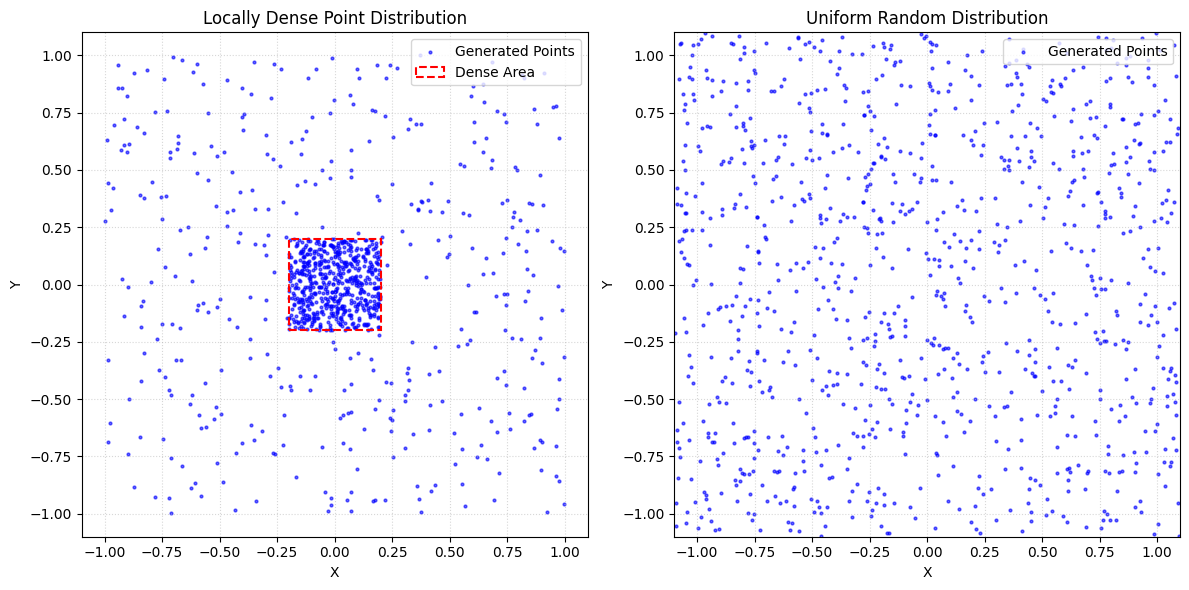

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

pts = coords.cpu().numpy()
num_points = len(pts)
uniform_pts = np.random.uniform(low=-1.1, high=1.1, size=(num_points, 2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.6, color='blue', label="Generated Points")
box = patches.Rectangle((box_x_min, box_y_min), box_w, box_h, 
                        fill=False, edgecolor='red', linestyle='--', linewidth=1.5, label="Dense Area")
ax1.add_patch(box)
ax1.set_xlim(-1.1, 1.1)
ax1.set_ylim(-1.1, 1.1)
ax1.set_title("Locally Dense Point Distribution")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend(loc="upper right")

ax2.scatter(uniform_pts[:, 0], uniform_pts[:, 1], s=4, alpha=0.6, color='blue', label="Generated Points")
ax2.set_xlim(-1.1, 1.1)
ax2.set_ylim(-1.1, 1.1)
ax2.set_title("Uniform Random Distribution")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [2]:
from physicsnemo.models.fno import KDTree, KDTreeNode


C:\Users\awars\AppData\Local\Temp\ipykernel_38452\844403738.py:62: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap  = get_cmap("tab20")


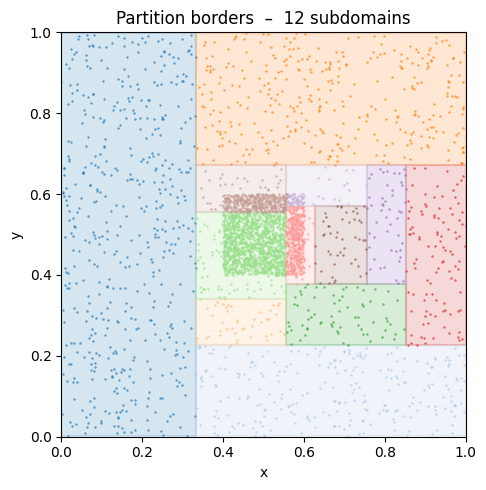

Done – saved kd_tree_bboxes.png and kd_tree_borders_darcy.png


In [24]:
import sys
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))

if parent_dir not in sys.path:
    sys.path.append(parent_dir)
from physicsnemo.models.fno import KDTree, KDTreeNode

import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.cm import get_cmap

# ── Point cloud setup ────────────────────────────────────────────────────────

points = coords_np.tolist()

def run_kdtree(n_subdomains):
    kd = KDTree(
        points,
        dim=2,
        n_subdomains=n_subdomains,
        n_blocks=8,
        smallest_points=8,
        max_depth=None,
        group=1,
    )
    kd.solve()
    return kd

# ── Plotting helper ───────────────────────────────────────────────────────────
def draw_decomposition(ax, kd, title, show_points=True, alpha_box=0.25):
    """Draw bounding boxes and (optionally) scatter points, coloured by subdomain."""
    cmap  = get_cmap("tab20")
    nodes = kd.nodes

    for idx, node in enumerate(nodes):
        color = cmap(idx % 20)
        (x0, x1), (y0, y1) = node.bbox
        rect = patches.Rectangle(
            (x0, y0), x1 - x0, y1 - y0,
            linewidth=1.2, edgecolor=color,
            facecolor=color, alpha=alpha_box,
        )
        ax.add_patch(rect)

        if show_points:
            pts = node.points_np
            ax.scatter(pts[:, 0], pts[:, 1],
                       color=color, s=3, alpha=0.7, linewidths=0)

    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("x"); ax.set_ylabel("y")


def draw_borders(ax, kd, title, show_points=True, alpha_box=0.18):
    """Draw split *borders* (the full hierarchical partition cells) instead of bounding boxes."""
    cmap  = get_cmap("tab20")
    nodes = kd.nodes
    borders = kd.get_subdomain_borders()

    for idx, (node, border) in enumerate(zip(nodes, borders)):
        color = cmap(idx % 20)
        (x0, x1) = border[0]
        (y0, y1) = border[1]
        rect = patches.Rectangle(
            (x0, y0), x1 - x0, y1 - y0,
            linewidth=1.5, edgecolor=color,
            facecolor=color, alpha=alpha_box,
        )
        ax.add_patch(rect)

        if show_points:
            pts = node.points_np
            ax.scatter(pts[:, 0], pts[:, 1],
                       color=color, s=3, alpha=0.7, linewidths=0)

    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("x"); ax.set_ylabel("y")


# ── Build trees with different subdomain counts ───────────────────────────────
kd_12  = run_kdtree(12)
kd_32  = run_kdtree(32)


fig2, axs2 = plt.subplots(1, 1, figsize=(17, 5))

draw_borders(axs2, kd_12, "Partition borders  –  12 subdomains")
plt.tight_layout()
plt.savefig("kd_tree_borders.png", dpi=300, bbox_inches="tight")
plt.show()

print("Done – saved kd_tree_bboxes.png and kd_tree_borders_darcy.png")